In [24]:
import pandas as pd                                          # trae la librería Pandas con el apodo "pd"
df = pd.read_csv("desafiopinguinos.csv", sep=";")            # lee el archivo y lo guarda en "df" (la tabla)
print(df.shape)                                              # muestra (filas, columnas)

(1000, 7)


In [25]:
df.head()                                                    # muestra las primeras 5 filas de la tabla

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male


In [26]:
df.isna().sum()                                              # cuenta cuántos datos vacíos hay en cada columna

species               0
island                0
culmen_length_mm     10
culmen_depth_mm      10
flipper_length_mm    10
body_mass_g          10
sex                  10
dtype: int64

In [27]:
df = df.dropna()                                             # borra las filas que tengan algún dato vacío
print(df.shape)                                              # revisa cuántas filas quedaron

(951, 7)


In [28]:
df = df.sample(n=85, random_state=42)                        # toma 85 filas al azar y las guarda en df
print(df.shape)                                              # revisa cuántas filas quedaron

(85, 7)


In [29]:
promedio = df["body_mass_g"].mean()                          # promedio del peso (en gramos)
desviacion = df["body_mass_g"].std()                         # desviación estándar del peso
print("Promedio del peso:", round(promedio, 2))              # lo muestra con 2 decimales
print("Desviación estándar:", round(desviacion, 2))          # lo muestra con 2 decimales

Promedio del peso: 4144.94
Desviación estándar: 712.65


In [30]:
casos_por_isla = df["island"].value_counts()                 # cuenta cuántos pingüinos hay en cada isla
print(casos_por_isla)                                        # muestra el resultado

island
Dream        48
Biscoe       26
Torgersen    11
Name: count, dtype: int64


In [31]:
df.to_excel("pinguinos_muestra.xlsx", index=False)           # guarda la tabla en un archivo Excel
print("Archivo guardado")                                     # avisa que terminó

Archivo guardado


In [32]:
promedio_casos = casos_por_isla.mean()                       # promedio de pingüinos por isla
islas_sobre_promedio = casos_por_isla[casos_por_isla > promedio_casos]   # deja solo las islas por encima del promedio
print("Promedio de casos por isla:", round(promedio_casos, 2))
print(islas_sobre_promedio)                                  # muestra esas islas

Promedio de casos por isla: 28.33
island
Dream    48
Name: count, dtype: int64


In [33]:
pesados = df[df["body_mass_g"] > 4500]                       # deja solo los pingüinos de más de 4500 g
print("Pingüinos de más de 4500 g:", len(pesados))           # cuenta cuántos son
print(pesados["species"].value_counts())                     # cuenta cuántos hay de cada especie
print(pesados["island"].value_counts())                      # cuenta cuántos hay en cada isla

Pingüinos de más de 4500 g: 24
species
Gentoo    24
Name: count, dtype: int64
island
Biscoe    24
Name: count, dtype: int64


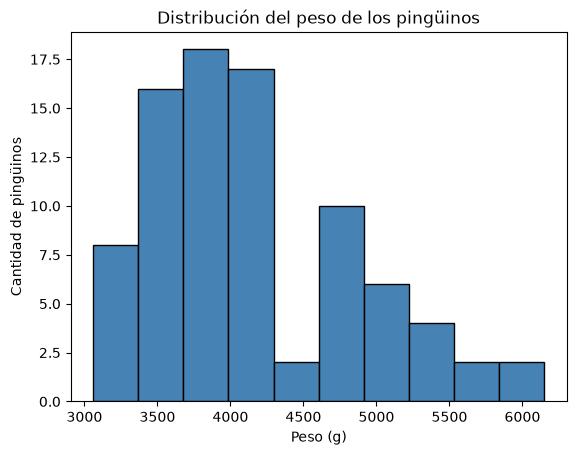

In [34]:
import matplotlib.pyplot as plt                         # traigo la herramienta para hacer gráficos

plt.hist(df["body_mass_g"], bins=10,                    # histograma del peso; bins=10 son 10 cajones
         color="steelblue", edgecolor="black")          # color de las barras y borde negro para verlas bien
plt.title("Distribución del peso de los pingüinos")     # título del gráfico
plt.xlabel("Peso (g)")                                  # nombre del eje x
plt.ylabel("Cantidad de pingüinos")                     # nombre del eje y
plt.savefig("histograma_peso.png")                      # guardo la imagen (SIEMPRE antes de show)
plt.show()                                              # muestro el gráfico en el notebook

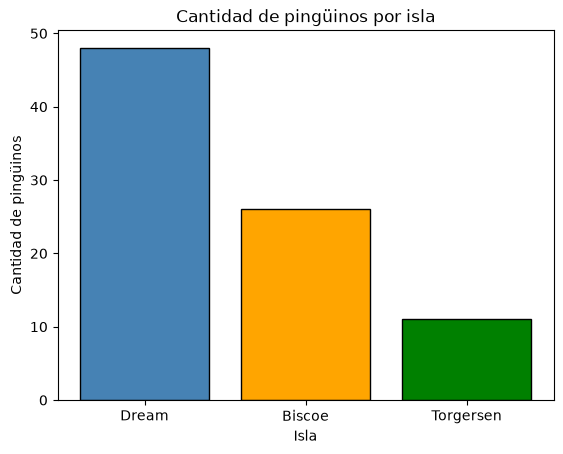

In [35]:
casos_por_isla = df["island"].value_counts()               # cuento cuántos pingüinos hay en cada isla

plt.bar(casos_por_isla.index, casos_por_isla.values,       # x = nombres de las islas, y = cantidades
        color=["steelblue", "orange", "green"],            # un color distinto para cada barra
        edgecolor="black")                                 # borde negro para que se vean bien
plt.title("Cantidad de pingüinos por isla")                # título del gráfico
plt.xlabel("Isla")                                         # nombre del eje x
plt.ylabel("Cantidad de pingüinos")                        # nombre del eje y
plt.savefig("barras_isla.png")                             # guardo la imagen antes de show
plt.show()                                                 # muestro el gráfico

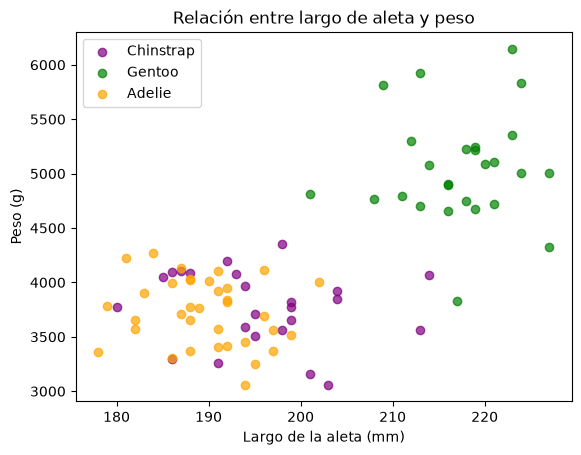

In [36]:
colores = {"Adelie": "orange", "Chinstrap": "purple", "Gentoo": "green"}   # un color para cada especie

for especie in df["species"].unique():                                     # repito esto para cada especie
    grupo = df[df["species"] == especie]                                   # me quedo solo con esa especie
    plt.scatter(grupo["flipper_length_mm"], grupo["body_mass_g"],          # x = aleta, y = peso
                color=colores[especie], label=especie, alpha=0.7)          # color, nombre en la leyenda, transparencia

plt.title("Relación entre largo de aleta y peso")                          # título del gráfico
plt.xlabel("Largo de la aleta (mm)")                                       # nombre del eje x
plt.ylabel("Peso (g)")                                                     # nombre del eje y
plt.legend()                                                               # muestra qué color es cada especie
plt.savefig("dispersion_aleta_peso.png")                                   # guardo la imagen antes de show
plt.show()                                                                 # muestro el gráfico